# Week5_ex2_analysis — Do pre-fault loads matter for three-phase fault currents?

Deep dive. PowerWorld keeps every load in the fault calculation as a constant admittance at its pre-fault voltage,

$$Y_{load} = \frac{S_{load}^*}{|V_0|^2}, \qquad I_F = \frac{V_0}{Z_{kk}},$$

while the textbook's classical method and IEC 60909 (`calc_sc`) leave loads out. Week5_ex1 had no load, so the question never came up. On the loaded 37-bus system this notebook measures what dropping the loads does, where the effect comes from, and whether `calc_sc` stays on the safe side.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from case37 import BUSES, build_case, solve_pw
from fault37 import pw_fault_table, fault_results, fault_zbus, calc_sc_currents

# 1. FutureWarning from pandas inside pandapower's branch builder; it prints the local install path
warnings.filterwarnings("ignore", category=FutureWarning)

# 2. Pre-fault state and the two classical variants
net = solve_pw(build_case(), numba=False)
pw = pw_fault_table()
with_loads = fault_results(net, loads=True)
no_loads = fault_results(net, loads=False)

meas = pd.DataFrame({"PowerWorld [pu]": pw["I [pu]"],
                     "With loads [pu]": with_loads.loc[pw.index, "I [pu]"],
                     "No loads [pu]": no_loads.loc[pw.index, "I [pu]"]})
meas["With loads err [%]"] = (meas["With loads [pu]"] / meas["PowerWorld [pu]"] - 1) * 100
meas["No loads err [%]"] = (meas["No loads [pu]"] / meas["PowerWorld [pu]"] - 1) * 100
meas.sort_values("No loads err [%]").round(4)

,PowerWorld [pu],With loads [pu],No loads [pu],With loads err [%],No loads err [%]
bus,,,,,
18,11.5905,11.5905,10.9802,0.0000,-5.2658
37,11.0354,11.0354,10.4798,0.0000,-5.0339
15,37.6010,37.6009,35.9524,-0.0005,-4.3846
54,39.0183,39.0181,37.4119,-0.0005,-4.1171
16,31.1477,31.1476,29.9230,-0.0004,-3.9322
12,25.1072,25.1071,24.2095,-0.0004,-3.5752
55,11.5659,11.5659,11.1614,0.0000,-3.4977
27,25.2572,25.2571,24.3856,-0.0003,-3.4507
48,29.0131,29.0130,28.0653,-0.0004,-3.2670


## Hypothesis 1

Loads can be neglected: a few percent of the short-circuit level each, they should change the fault current by less than 1%.

In [2]:
# 3. Load share at each bus = load MVA / short-circuit MVA
load_mva = net.res_load.groupby(net.load.bus).apply(lambda d: np.hypot(d.p_mw, d.q_mvar).sum())
s_sc = meas["PowerWorld [pu]"] * net.res_bus.vm_pu[pw.index] * 100
h1 = pd.DataFrame({"Load / S_sc [%]": (load_mva.reindex(pw.index).fillna(0) / s_sc * 100),
                   "No loads err [%]": meas["No loads err [%]"]})
pd.DataFrame({"Min": h1.min(), "Max": h1.max()}).assign(
    **{"Buses beyond 1 %": [np.nan, (h1["No loads err [%]"] < -1).sum()]}).round(3)

,Min,Max,Buses beyond 1 %
Load / S_sc [%],0.000,4.611,NaN
No loads err [%],-5.266,-0.576,31.0


**Verdict: rejected.** Without loads every one of the 37 currents comes out low, by 0.6–5.3% (bus 18, WALNUT69). Thirty-one buses miss by more than 1%, and the error is in the unsafe direction for breaker duty.

## Hypothesis 2

The error comes from the load at the faulted bus itself, so adding back only that one load should recover most of the gap.

In [3]:
# 4. Keep only the faulted bus's own load, one fault at a time
order = [b for b, _, _ in BUSES]
z_none, v0 = fault_zbus(net, loads=False)
y_none = np.linalg.inv(z_none)
vm = np.abs(v0)
own = {}
for b in pw.index:
    k = order.index(b)
    y = y_none.copy()
    for i in net.load.index[net.load.bus == b]:
        s = complex(net.res_load.at[i, "p_mw"], net.res_load.at[i, "q_mvar"]) / 100
        y[k, k] += np.conj(s) / vm[k] ** 2
    own[b] = abs(v0[k] / np.linalg.inv(y)[k, k])
h2 = pd.DataFrame({"Has own load": pw.index.isin(net.load.bus),
                   "No loads err [%]": meas["No loads err [%]"],
                   "Own load only err [%]": (pd.Series(own) / meas["PowerWorld [pu]"] - 1) * 100})
h2.sort_values(["Has own load", "No loads err [%]"]).round(3)

,Has own load,No loads err [%],Own load only err [%]
40,False,-2.919,-2.919
47,False,-2.739,-2.739
39,False,-2.096,-2.096
41,False,-2.094,-2.094
38,False,-1.370,-1.370
31,False,-1.333,-1.333
1,False,-1.261,-1.261
32,False,-1.256,-1.256
29,False,-0.845,-0.845
35,False,-0.839,-0.839


**Verdict: rejected.** The eleven buses with no load at all still miss by up to 2.9% (bus 40, OAK138), and at loaded buses the own load closes only part of the gap (bus 18: −5.3% → −2.8%). The loads act through the whole network: together they lower the Thevenin impedance everywhere, so a per-bus correction cannot replace the full model.

## Hypothesis 3

`calc_sc` with default settings (IEC maximum case) ignores loads, but its voltage factor still keeps every current above PowerWorld's, so it remains a safe screen for breaker duty on a loaded system.

In [4]:
# 5. Rated power factor 0.85 is assumed for every generator (the case does not carry one).
#    calc_sc warns that the off-nominal transformer ratios block fault voltages and branch flows;
#    only bus currents are used here, so the warning is silenced for this call
with warnings.catch_warnings():
    warnings.simplefilter("ignore", UserWarning)
    iec = calc_sc_currents(gen_cos_phi=0.85)
h3 = pd.DataFrame({"PowerWorld [pu]": meas["PowerWorld [pu]"],
                   "calc_sc IEC max [pu]": iec.loc[pw.index]})
h3["IEC err [%]"] = (h3["calc_sc IEC max [pu]"] / h3["PowerWorld [pu]"] - 1) * 100
assert (h3["IEC err [%]"] > 0).all()
h3.sort_values("IEC err [%]").head(8).round(3)

,PowerWorld [pu],calc_sc IEC max [pu],IEC err [%]
bus,,,
28,64.025,64.958,1.458
31,54.346,55.737,2.559
48,29.013,29.976,3.320
54,39.018,40.372,3.471
53,43.193,44.745,3.593
15,37.601,39.039,3.825
38,40.991,42.641,4.026
12,25.107,26.127,4.062


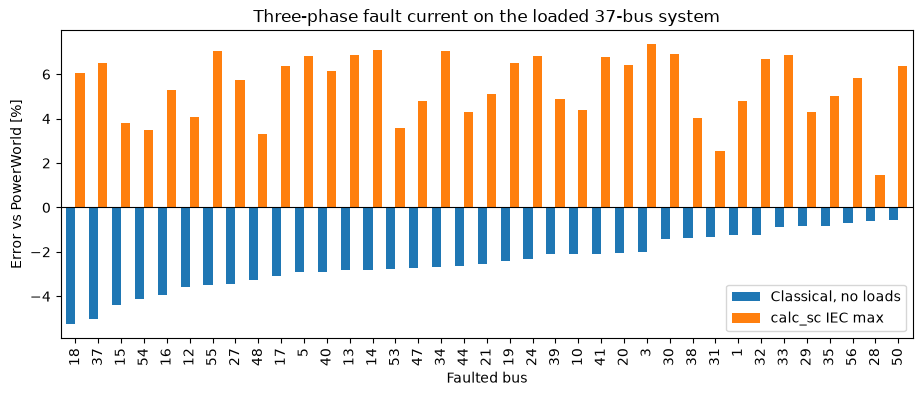

In [5]:
# 6. Error of each method against PowerWorld, buses sorted by the no-load error
plot = pd.DataFrame({"Classical, no loads": meas["No loads err [%]"],
                     "calc_sc IEC max": h3["IEC err [%]"]}).sort_values("Classical, no loads")
ax = plot.plot.bar(figsize=(11, 4), width=0.8)
ax.axhline(0, color="black", lw=0.8)
ax.set_xlabel("Faulted bus")
ax.set_ylabel("Error vs PowerWorld [%]")
ax.set_title("Three-phase fault current on the loaded 37-bus system")
plt.savefig("Images/Week5_ex2_load_effect_fault_current.png", dpi=150, bbox_inches="tight")
plt.show()

**Verdict: accepted.** `calc_sc` sits 1.5–7.3% above PowerWorld at every bus. The margin is thinnest at the large generator buses (ELM345 +1.5%, SLACK345 +2.6%), where loads matter least but the IEC generator correction bites hardest.

## Final conclusion

- PowerWorld's fault analysis is the classical method **with loads kept as constant admittances** at their pre-fault voltages; the 37-bus results reproduce to the printed digit only with that model.
- Dropping the loads underestimates every fault current on this system, by up to 5.3%. The effect is network-wide, not local to the faulted bus.
- `calc_sc` ignores loads too, but its IEC voltage factor more than covers the gap here: it stays 1.5–7.3% above PowerWorld.

**Rules for the project:** on this system `calc_sc` defaults cover the load effect with a 1.5–7.3% margin, but that margin is a property of the system, not of `calc_sc`: check it against the hand-built Zbus (loads included) on every new network, and report the generator buses separately because their margin is the thinnest. Any hand-built Zbus used for comparison or for fault voltages must include the loads as $S^*/|V_0|^2$ — the load-free textbook shortcut is not conservative.